In [1]:
# coding=utf-8
import numpy as np
import pandas as pd
import seaborn as sns
from operator import add
from functools import reduce
import matplotlib.pyplot as plt
from numpy.random import uniform
from lib.bandits import Bernoulli, Gaussian
from lib.policies import p_auer, p_ape, p_unif
x = 0.05
xx = 0.1
means = np.concatenate((np.array([
    [0.5, 0.5],
    [0.5+xx, 0.5-xx],
    [0.5+x+xx,0.5-x-xx],
]), np.random.uniform(0,0.4, size=(2, 2))))
K = 5
D = 2
inf = 1e12
l_eps = [0, 0.05, 0.1, 0.2, 0.25]
bandit = Bernoulli(means)
psi_ape = p_ape(bandit)
print("[complexity]: ", bandit.H)
print("[pareto set]: ", bandit.optimal_arms)

[complexity]:  930.2569721730604
[pareto set]:  [0, 1, 2]


In [2]:
numiter = 2000
seeds = (np.random.uniform(size=numiter)*2**31).astype(np.uint)
delta = 0.01
eps_1 = 0.
m = K

In [62]:
res_psi_ape = []
for eps_2 in l_eps:
    print(eps_2)
    res_ = []
    for seed in seeds:
        res_  += [sum(psi_ape.loop(seed, delta, eps_1, eps_2, m)[0][1])]
    res_psi_ape += [res_]
for k, eps_2 in enumerate(l_eps):
    print("[eps_2=%f] [APE]:"%eps_2, np.mean(res_psi_ape[k], axis=0))

0
0.05
0.1
0.2
0.25
[eps_2=0.000000] [APE]: 24298.492
[eps_2=0.050000] [APE]: 23578.608
[eps_2=0.100000] [APE]: 19930.914
[eps_2=0.200000] [APE]: 17505.292
[eps_2=0.250000] [APE]: 10560.372


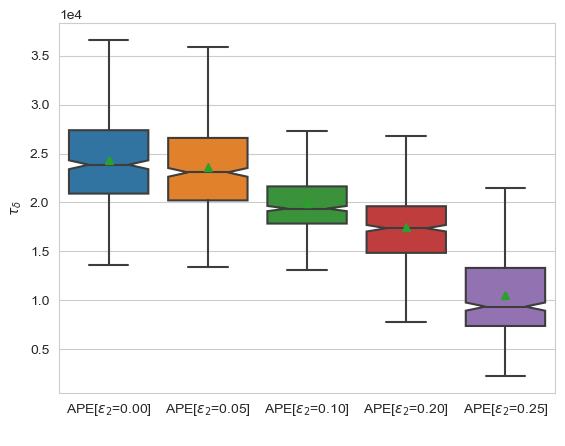

In [63]:
data = np.concatenate((*res_psi_ape,))
df = pd.DataFrame({"sc": data, "names": reduce(add, [[r"APE[$\epsilon_2$=%.2f]"%eps_2]*seeds.size for eps_2 in l_eps]) })
sns.boxplot(data=df, x="names", y="sc",  orient="v", showmeans=True, showfliers=False, notch=True).set(
    xlabel=' ',
    ylabel=r'$\tau_{\delta}$')
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))

In [25]:
res_ = []
for seed in seeds:
    res_  += [psi_ape.loop(seed, delta, eps_1, eps_2=0.4, m=K)[1]]
res_eps1 = reduce(add, res_)

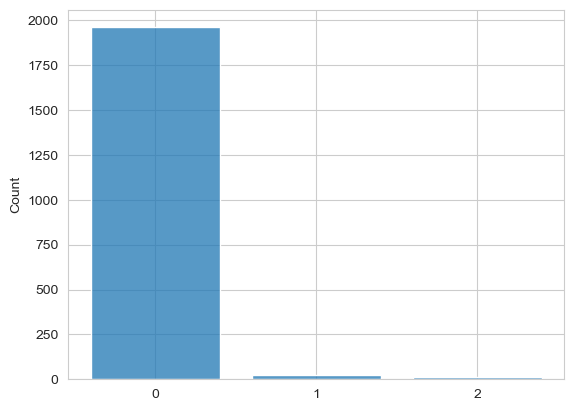

In [27]:
fig = sns.histplot(res_eps1,  discrete=True, shrink=0.8, stat="count")
fig.set_xticks([0, 1, 2])

In [21]:
res_ = []
for seed in seeds:
    res_  += [sum(psi_ape.loop(seed, delta, eps_1=0, eps_2=0., m=1)[0][1])]
print("APE[k=1] :", np.mean(res_))

APE[k=1] : 4073.404


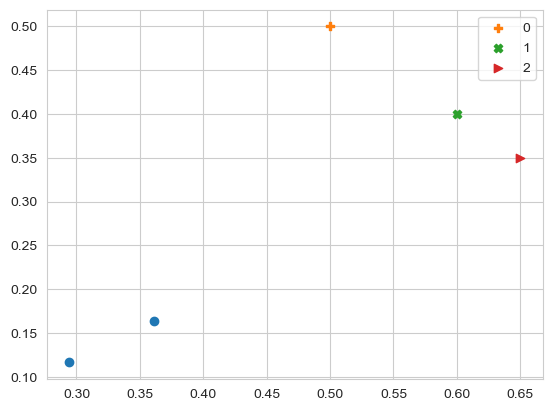

In [19]:
sns.set_style("whitegrid")
plt.scatter(*means[3:].T, marker="o")
markers = ["P", "X", ">"]
for i in range(3):
    plt.scatter(*means[i], marker=markers[i], label=f"{i}")
plt.legend()

In [16]:
res_psi_ape = []
val_tau = []
val_length = []
x = np.linspace(0, 0.5, 50)
for eps_2 in x:
    res_ = []
    res__ = []
    for seed in seeds:
        res = psi_ape.loop(seed, delta, eps_1, eps_2, m)
        res_  += [sum(res[0][1])]
        res__ += [len(res[1])]
    val_tau += [np.mean(res_)]
    val_length += [np.mean(res__)]

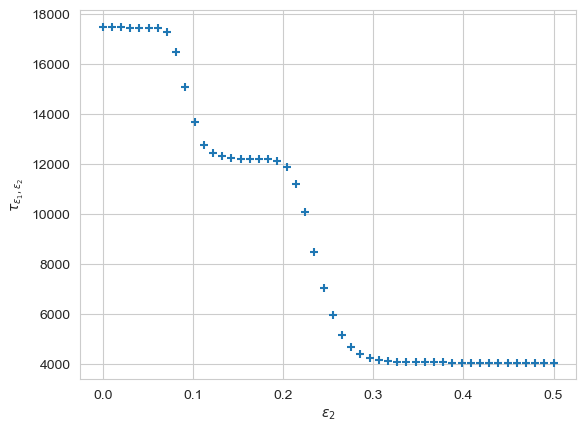

In [17]:
plt.xlabel(r"$\varepsilon_2$")
plt.ylabel(r"$\tau_{\varepsilon_1, \varepsilon_2}$")
plt.scatter(x, val_tau, marker="+")

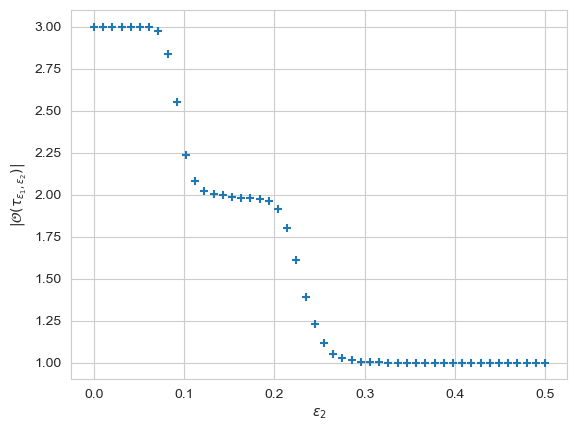

In [18]:
plt.xlabel(r"$\varepsilon_2$")
plt.ylabel(r"$|\mathcal{O}({\tau_{\varepsilon_1, \varepsilon_2}})|$")
plt.scatter(x, val_length, marker="+")